# Final comparison — selected features

So sánh test artifacts có cùng frozen data contract và cùng node features. Đồng thời hiển thị validation evidence của graph, edge factorial và negative controls.

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'modeling-common').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'modeling-common'))
import forecast_ablation as fa

ctx = fa.load_context(ROOT)
GAT = ROOT / 'artifacts' / 'gatgru' / 'v05_selected_features_final' / 'gatgru_selected_predictions_test.npz'
LSTM = ROOT / 'artifacts' / 'lstm' / 'v01_shared_selected_features' / 'lstm_shared_predictions_test.npz'
OUT = ROOT / 'artifacts' / 'comparison' / 'v01_selected_features'
metrics, summary = fa.compare_final_predictions(GAT, LSTM, OUT, ctx=ctx)
display(summary)

# Post-hoc only: use these test results for description, never for tuning/model selection.
# Block-bootstrap CI measures within-run temporal variation, not between-run generalization.
display(pd.read_csv(OUT / 'scenario_mae_and_mase_posthoc.csv'))
display(pd.read_csv(OUT / 'scenario_delta_block_bootstrap_posthoc.csv'))
display(pd.read_csv(OUT / 'seed_variability_vs_effect_posthoc.csv'))
display(pd.read_csv(OUT / 'diagnostic_high_load_transition.csv'))
display(pd.read_csv(OUT / 'paired_run_sign_test.csv'))

,model,target,MAE_mean,MAE_std,RMSE_mean,RMSE_std,under_MAE_mean,over_MAE_mean
0,gatgru,cpu_cores,0.012846,0.000151,0.036806,0.000646,0.006864,0.005982
1,gatgru,rps_in,1.000115,0.012294,3.019753,0.031732,0.612346,0.387770
2,lstm,cpu_cores,0.012625,0.000238,0.036759,0.000593,0.007065,0.005561
3,lstm,rps_in,0.962985,0.021266,2.952503,0.038571,0.557037,0.405948


,model,baseline,scenario,target,MAE,MASE,mase_valid_service_count
0,gatgru,mean_across_seed_metrics,mmpp,rps_in,1.846164,1.533169,10
1,gatgru,mean_across_seed_metrics,mmpp,cpu_cores,0.021619,2.056136,11
2,gatgru,mean_across_seed_metrics,nhpp,rps_in,0.881762,0.913371,10
3,gatgru,mean_across_seed_metrics,nhpp,cpu_cores,0.012552,1.453772,11
4,gatgru,mean_across_seed_metrics,onoff,rps_in,0.635595,0.740374,10
5,gatgru,mean_across_seed_metrics,onoff,cpu_cores,0.008535,1.126988,11
6,gatgru,mean_across_seed_metrics,pareto,rps_in,0.634452,1.007543,10
7,gatgru,mean_across_seed_metrics,pareto,cpu_cores,0.008650,1.418480,11
8,lstm,mean_across_seed_metrics,mmpp,rps_in,1.813772,1.495389,10
9,lstm,mean_across_seed_metrics,mmpp,cpu_cores,0.021488,1.738438,11


,scenario,target,gatgru_minus_lstm_mae,ci95_low,ci95_high,block_len_windows,n_boot,test_runs
0,mmpp,rps_in,0.032392,-0.078563,0.156563,6,2000,1
1,nhpp,rps_in,0.066927,0.018456,0.114525,6,2000,1
2,onoff,rps_in,0.019916,0.007294,0.035159,6,2000,1
3,pareto,rps_in,0.029232,0.013990,0.040782,6,2000,1
4,mmpp,cpu_cores,0.000131,-0.000599,0.000861,6,2000,1
5,nhpp,cpu_cores,0.000206,-0.000277,0.000763,6,2000,1
6,onoff,cpu_cores,0.000115,-0.000093,0.000328,6,2000,1
7,pareto,cpu_cores,0.000432,0.000138,0.000672,6,2000,1


,model,target,scenario,seed,MAE,gatgru_seed_sd,lstm_seed_sd,delta_over_max_seed_sd
0,gatgru,rps_in,mmpp,0.0,1.782397,NaN,NaN,NaN
1,gatgru,rps_in,mmpp,1.0,1.829805,NaN,NaN,NaN
2,gatgru,rps_in,mmpp,2.0,1.908205,NaN,NaN,NaN
3,gatgru,rps_in,mmpp,3.0,1.851261,NaN,NaN,NaN
4,gatgru,rps_in,mmpp,4.0,1.859152,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
83,lstm,cpu_cores,pareto,1.0,0.008248,NaN,NaN,NaN
84,lstm,cpu_cores,pareto,2.0,0.008237,NaN,NaN,NaN
85,lstm,cpu_cores,pareto,3.0,0.008182,NaN,NaN,NaN
86,lstm,cpu_cores,pareto,4.0,0.008208,NaN,NaN,NaN


,model,seed,target,slice,n_points,MAE,under_MAE,over_MAE
0,gatgru,0,rps_in,high_load,8095,1.674268,1.601626,0.072641
1,gatgru,0,rps_in,transition_onset,4620,2.206824,2.022130,0.184695
2,gatgru,0,cpu_cores,high_load,4202,0.030848,0.028315,0.002532
3,gatgru,0,cpu_cores,transition_onset,4230,0.028044,0.023812,0.004231
4,gatgru,1,rps_in,high_load,8095,1.647055,1.605740,0.041314
5,gatgru,1,rps_in,transition_onset,4620,2.199624,2.042241,0.157383
6,gatgru,1,cpu_cores,high_load,4202,0.030185,0.028478,0.001707
7,gatgru,1,cpu_cores,transition_onset,4230,0.027502,0.023047,0.004455
8,gatgru,2,rps_in,high_load,8095,1.646045,1.590870,0.055175
9,gatgru,2,rps_in,transition_onset,4620,2.185498,2.013333,0.172166


,target,gatgru_wins,test_run_pairs,sign_test_p,mean_lstm_minus_gatgru_mae
0,cpu_cores,0,4,0.125,-0.000221
1,rps_in,0,4,0.125,-0.037117


## Validation evidence used to attribute graph and edge effects
Run the extended v02 graph-controls validation notebook first; this section reads its validation-only output.

In [2]:
E = ROOT / 'artifacts' / 'gatgru'
evidence = {
    'graph': pd.read_csv(E / 'v02_graph_controls' / 'variant_summary.csv'),
    'edge_factorial': pd.read_csv(E / 'v03_edge_ablation' / 'variant_summary.csv'),
    'edge_controls': pd.read_csv(E / 'v04_edge_controls' / 'variant_summary.csv'),
}
graph_effects, edge_effects, control_effects = fa.summarize_validation_evidence(
    E / 'v02_graph_controls' / 'variant_summary.csv',
    E / 'v03_edge_ablation' / 'variant_summary.csv',
    E / 'v04_edge_controls' / 'variant_summary.csv',  # optional when no edge feature is selected
    OUT,
)
for name, table in evidence.items():
    print('\n', name)
    display(table[['variant', 'primary_score_mean', 'primary_score_std',
                   'cpu_weighted_diagnostic_mean', 'rps_in_mae_macro_mean',
                   'cpu_cores_mae_macro_mean', 'n_params_mean']])
print('\nGraph effect sizes (positive = named component helps)')
display(graph_effects)
print('\nEdge main effects (positive = edge feature helps)')
display(edge_effects.groupby('feature', as_index=False).mean(numeric_only=True))
print('\nNegative controls (positive = real edge values help)')
display(control_effects)

# Distribution over repeated validation topology shuffles and graph controls.
display(pd.read_csv(OUT / 'topology_shuffle_summary.csv'))
display(pd.read_csv(OUT / 'topology_control_effects.csv'))


 graph


,variant,primary_score_mean,primary_score_std,cpu_weighted_diagnostic_mean,rps_in_mae_macro_mean,cpu_cores_mae_macro_mean,n_params_mean
0,dynamic_all_edges,0.113994,0.001107,0.106535,1.008243,0.013603,121560.0
1,static_gat_shuffled_topology_seed_101,0.114035,0.000560,0.106558,1.001588,0.013578,121528.0
2,static_gat_shuffled_topology_seed_303,0.114091,0.000805,0.106821,1.002733,0.013665,121528.0
3,static_gat_shuffled_topology,0.114340,0.000671,0.106702,1.008615,0.013536,121528.0
4,static_gat,0.114503,0.000825,0.107162,1.006580,0.013711,121528.0
5,static_gat_shuffled_topology_seed_202,0.114830,0.000643,0.107232,1.017025,0.013668,121528.0
6,static_gat_full_directed,0.114959,0.000408,0.107308,1.012335,0.013623,121528.0
7,static_gat_random_same_density,0.115609,0.000482,0.108123,1.013026,0.013778,121528.0
8,static_gat_self_loops_only,0.118082,0.000484,0.110570,1.032978,0.014146,121528.0
9,gru_node_only,0.118488,0.000528,0.110963,1.035398,0.014178,121016.0



 edge_factorial


,variant,primary_score_mean,primary_score_std,cpu_weighted_diagnostic_mean,rps_in_mae_macro_mean,cpu_cores_mae_macro_mean,n_params_mean
0,edge_call_rate__call_ratio__edge_latency_p95_ms,0.113974,0.001562,0.106518,1.008904,0.013598,121560.0
1,edge_call_rate,0.114297,0.000959,0.106836,1.008749,0.013608,121544.0
2,edge_call_ratio,0.114346,0.000895,0.106854,1.008832,0.013600,121544.0
3,edge_none,0.114523,0.000858,0.107061,1.007476,0.013673,121528.0
4,edge_call_rate__call_ratio,0.114708,0.002667,0.107123,1.015701,0.013682,121552.0
5,edge_call_ratio__edge_latency_p95_ms,0.114839,0.002162,0.107227,1.018879,0.013682,121552.0
6,edge_call_rate__edge_latency_p95_ms,0.114960,0.002063,0.107354,1.019952,0.013708,121552.0
7,edge_edge_latency_p95_ms,0.114999,0.001463,0.107479,1.014769,0.013733,121544.0



 edge_controls


...

,feature,primary_score_improvement,cpu_weighted_diagnostic_improvement,rps_in_mae_macro_improvement,cpu_cores_mae_macro_improvement
0,call_rate,0.000192,0.000197,-0.000838,0.000023
1,call_ratio,0.000228,0.000252,-0.000343,0.000040
2,edge_latency_p95_ms,-0.000224,-0.000176,-0.005437,-0.000039



Negative controls (positive = real edge values help)


,control,positive_means_real_edges_better,primary_score_real_improvement,cpu_weighted_diagnostic_real_improvement,rps_in_mae_macro_real_improvement,cpu_cores_mae_macro_real_improvement
0,control_lag_6,True,-0.000125,-0.000151,-0.005735,-0.000032
1,control_edge_id_shuffle,True,0.000175,0.000237,-0.005326,0.000032
2,control_zero,True,0.000285,0.000306,-0.001771,0.000049
3,control_train_edge_mean,True,0.000431,0.000459,0.002479,0.000072


,metric,n_shuffles,mean_control_minus_real,std_across_shuffles,min_real_minus_shuffle,max_real_minus_shuffle
0,primary_score_control_minus_real,4,-0.000179,0.000362,-0.000468,0.000326
1,cpu_weighted_diagnostic_control_minus_real,4,-0.000334,0.000290,-0.000604,0.000070
2,rps_in_mae_macro_control_minus_real,4,0.000911,0.007063,-0.004992,0.010445
3,cpu_cores_mae_macro_control_minus_real,4,-0.000099,0.000065,-0.000175,-0.000043


,variant,primary_score_control_minus_real,cpu_weighted_diagnostic_control_minus_real,rps_in_mae_macro_control_minus_real,cpu_cores_mae_macro_control_minus_real
0,static_gat_shuffled_topology_seed_101,-0.000468,-0.000604,-0.004992,-0.000133
1,static_gat_shuffled_topology_seed_303,-0.000413,-0.000341,-0.003846,-0.000046
2,static_gat_shuffled_topology,-0.000164,-0.000460,0.002035,-0.000175
3,static_gat_shuffled_topology_seed_202,0.000326,0.000070,0.010445,-0.000043
4,static_gat_full_directed,0.000455,0.000146,0.005756,-0.000088
5,static_gat_random_same_density,0.001106,0.000961,0.006446,0.000067
6,static_gat_self_loops_only,0.003579,0.003408,0.026398,0.000434


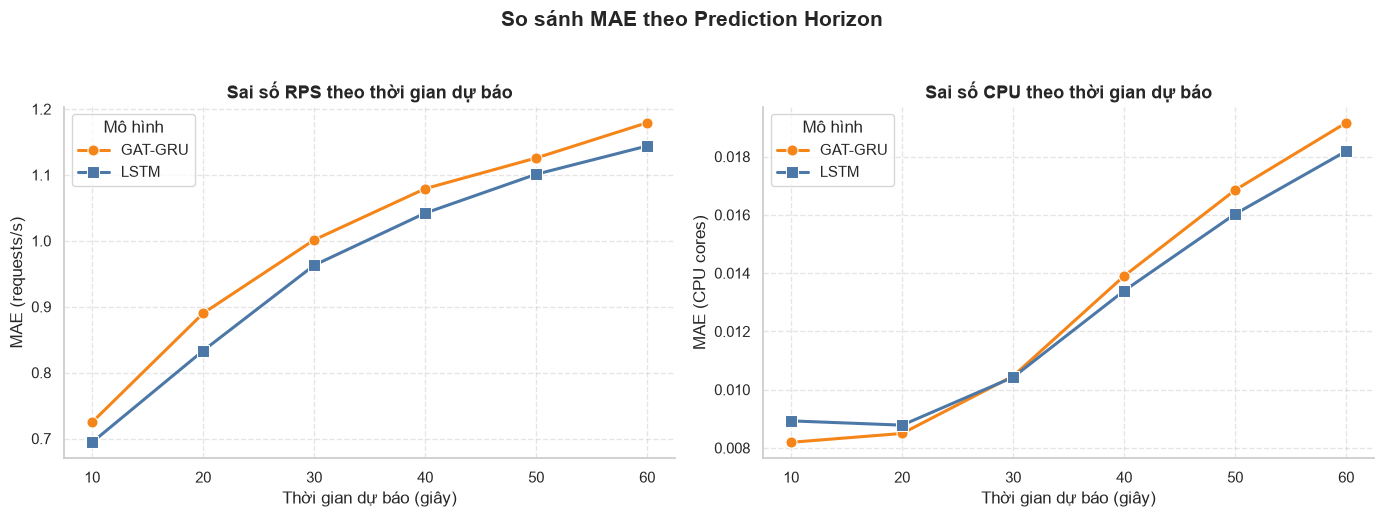

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = ROOT

METRICS_PATH = (
    PROJECT_ROOT
    / "artifacts"
    / "comparison"
    / "v01_selected_features"
    / "metrics_by_horizon.csv"
)

# Đọc MAE theo từng horizon và từng seed
metrics = pd.read_csv(METRICS_PATH)

# Tính MAE trung bình qua 5 seed
plot_df = (
    metrics.groupby(
        ["model", "target", "horizon_sec"],
        as_index=False,
    )["MAE"]
    .mean()
)

plot_df["Model"] = plot_df["model"].map({
    "gatgru": "GAT-GRU",
    "lstm": "LSTM",
})

model_order = ["GAT-GRU", "LSTM"]

palette = {
    "GAT-GRU": "#F58518",
    "LSTM": "#4C78A8",
}

markers = {
    "GAT-GRU": "o",
    "LSTM": "s",
}

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

# -------------------------------
# Biểu đồ 1: MAE của RPS
# -------------------------------
rps_df = plot_df[plot_df["target"] == "rps_in"]

sns.lineplot(
    data=rps_df,
    x="horizon_sec",
    y="MAE",
    hue="Model",
    style="Model",
    hue_order=model_order,
    style_order=model_order,
    palette=palette,
    markers=markers,
    dashes=False,
    linewidth=2.2,
    markersize=8,
    errorbar=None,
    ax=axes[0],
)

axes[0].set_title(
    "Sai số RPS theo thời gian dự báo",
    fontsize=13,
    fontweight="bold",
)
axes[0].set_xlabel("Thời gian dự báo (giây)")
axes[0].set_ylabel("MAE (requests/s)")
axes[0].set_xticks(sorted(rps_df["horizon_sec"].unique()))
axes[0].legend(title="Mô hình")
axes[0].grid(True, linestyle="--", alpha=0.5)

# -------------------------------
# Biểu đồ 2: MAE của CPU
# -------------------------------
cpu_df = plot_df[plot_df["target"] == "cpu_cores"]

sns.lineplot(
    data=cpu_df,
    x="horizon_sec",
    y="MAE",
    hue="Model",
    style="Model",
    hue_order=model_order,
    style_order=model_order,
    palette=palette,
    markers=markers,
    dashes=False,
    linewidth=2.2,
    markersize=8,
    errorbar=None,
    ax=axes[1],
)

axes[1].set_title(
    "Sai số CPU theo thời gian dự báo",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Thời gian dự báo (giây)")
axes[1].set_ylabel("MAE (CPU cores)")
axes[1].set_xticks(sorted(cpu_df["horizon_sec"].unique()))
axes[1].legend(title="Mô hình")
axes[1].grid(True, linestyle="--", alpha=0.5)

fig.suptitle(
    "So sánh MAE theo Prediction Horizon",
    fontsize=15,
    fontweight="bold",
    y=1.03,
)

sns.despine()
plt.tight_layout()
plt.show()